# 09b — Applicability-domain analysis with three methods

This stage reruns applicability-domain analysis using (1) standardized 5-nearest-neighbor distance, (2) the training-feature bounding box, and (3) leverage with the warning threshold h*=3p/n. It evaluates inside/outside test performance for the three Stage 08 models from saved predictions. It does not refit models and does not run Y-randomization.

Required: Stages 03, 04, 05, and 08 outputs, including the Stage 08 training OOF predictions for ExtraTrees. All feature scaling and AD limits are estimated from training data only.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: c:\Users\USER\Documents\E\Code


In [2]:
from src.applicability_domain import run
coverage, performance, knn_performance, test_ad = run()
coverage

Applicability-domain coverage (no model refitting, no Y-randomization):
                       method  threshold  n_inside_ad  n_outside_ad  fraction_inside_ad
   Standardized 5-NN distance    14.1157         1245            38              0.9704
Training-feature bounding box        NaN         1258            25              0.9805
         Leverage (hat value)     0.1461         1248            35              0.9727
      Max Tanimoto similarity     0.5090         1231            52              0.9595
 Consensus (inside >= 3 of 4)        NaN         1256            27              0.9790

Primary model (lowest Stage 07 CV RMSE): SVR
                       method  n_inside  n_outside  rmse_inside  rmse_outside  rmse_outside_minus_inside  ci_low  ci_high
   Standardized 5-NN distance      1245         38        0.551         0.849                      0.298   0.077    0.509
Training-feature bounding box      1258         25        0.554         0.878                      0.324   0.0

,method,method_key,threshold_rule,threshold,n_train,n_test,n_inside_ad,n_outside_ad,fraction_inside_ad
0,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,5134,1283,1245,38,0.970382
1,Training-feature bounding box,bounding_box,all 250 features within training min/max,NaN,5134,1283,1258,25,0.980514
2,Leverage (hat value),leverage,h* = 3 * rank(design) / n_train,0.146085,5134,1283,1248,35,0.972720
3,Max Tanimoto similarity,similarity,max Tanimoto >= 5th percentile of training (ot...,0.508979,5134,1283,1231,52,0.959470
4,Consensus (inside >= 3 of 4),consensus,inside at least 3 of the 4 methods,NaN,5134,1283,1256,27,0.978956


In [3]:
knn_performance

,Model,R2_All,R2_Inside_AD,R2_Outside_AD,N_Inside,N_Outside,RMSE_All,RMSE_Inside_AD,RMSE_Outside_AD,MAE_All,MAE_Inside_AD,MAE_Outside_AD
0,ExtraTreesRegressor,0.800836,0.808861,0.602390,1245,38,0.577079,0.561466,0.956769,0.400934,0.390184,0.753132
1,CatBoostRegressor,0.798095,0.804424,0.639303,1245,38,0.581036,0.567945,0.911276,0.414441,0.405917,0.693705
2,SVR,0.811054,0.815945,0.686661,1245,38,0.562081,0.550962,0.849349,0.395399,0.387620,0.650284
3,Equal-weight ensemble (supplementary),0.817015,0.822877,0.670149,1245,38,0.553143,0.540488,0.871440,0.388300,0.379770,0.667782


In [4]:
performance

,method,method_key,threshold_rule,threshold,model,domain_status,n_molecules,n_scaffold_groups,fraction_of_test,r2,rmse,mae,rmse_ci_low,rmse_ci_high
0,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,ExtraTreesRegressor,inside,1245,512,0.970382,0.808861,0.561466,0.390184,0.507081,0.612756
1,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,ExtraTreesRegressor,outside,38,34,0.029618,0.602390,0.956769,0.753132,0.704239,1.191372
2,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,CatBoostRegressor,inside,1245,512,0.970382,0.804424,0.567945,0.405917,0.514359,0.619823
3,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,CatBoostRegressor,outside,38,34,0.029618,0.639303,0.911276,0.693705,0.676855,1.121945
4,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,SVR,inside,1245,512,0.970382,0.815945,0.550962,0.387620,0.504623,0.594032
5,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,SVR,outside,38,34,0.029618,0.686661,0.849349,0.650284,0.630776,1.056487
6,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,Equal-weight ensemble (supplementary),inside,1245,512,0.970382,0.822877,0.540488,0.379770,0.489647,0.587442
7,Standardized 5-NN distance,knn,training (other-group) mean + 2 SD of 5-NN dis...,14.115684,Equal-weight ensemble (supplementary),outside,38,34,0.029618,0.670149,0.871440,0.667782,0.646761,1.080546
8,Training-feature bounding box,bounding_box,all 250 features within training min/max,NaN,ExtraTreesRegressor,inside,1258,519,0.980514,0.801975,0.572242,0.396988,0.519086,0.621440
9,Training-feature bounding box,bounding_box,all 250 features within training min/max,NaN,ExtraTreesRegressor,outside,25,20,0.019486,0.737042,0.782768,0.599509,0.532336,1.061444


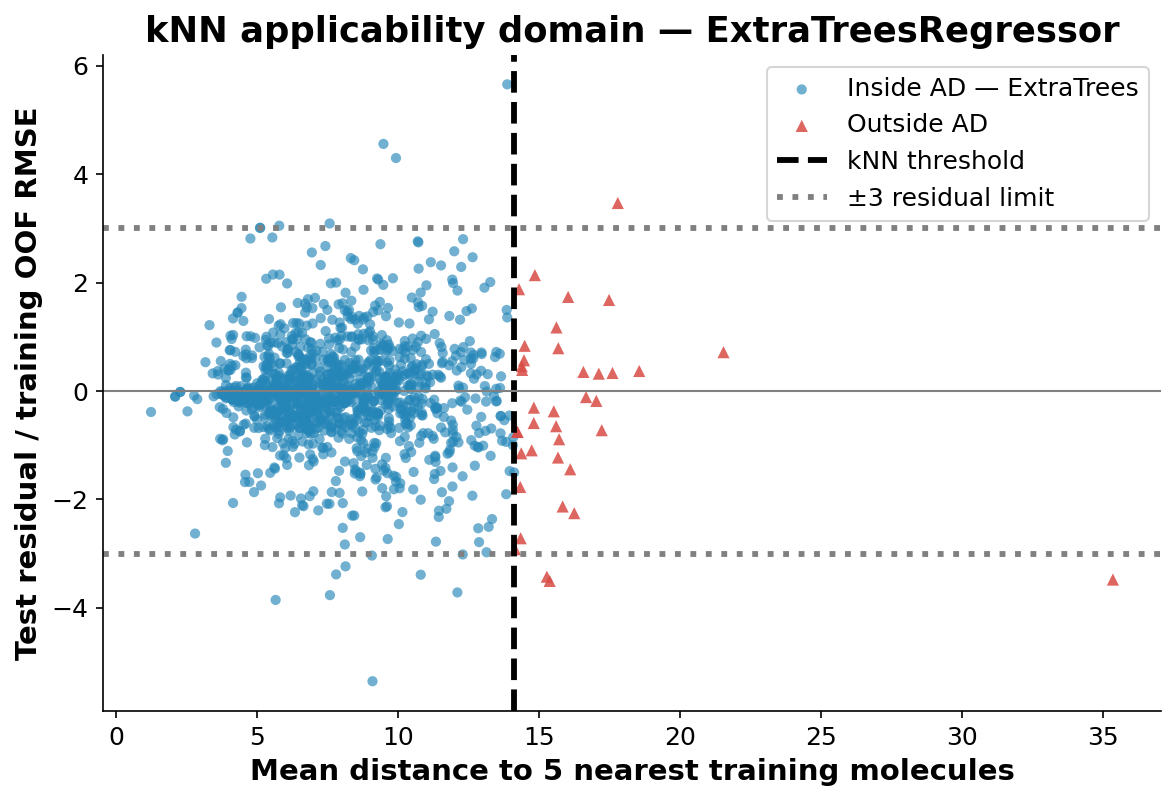

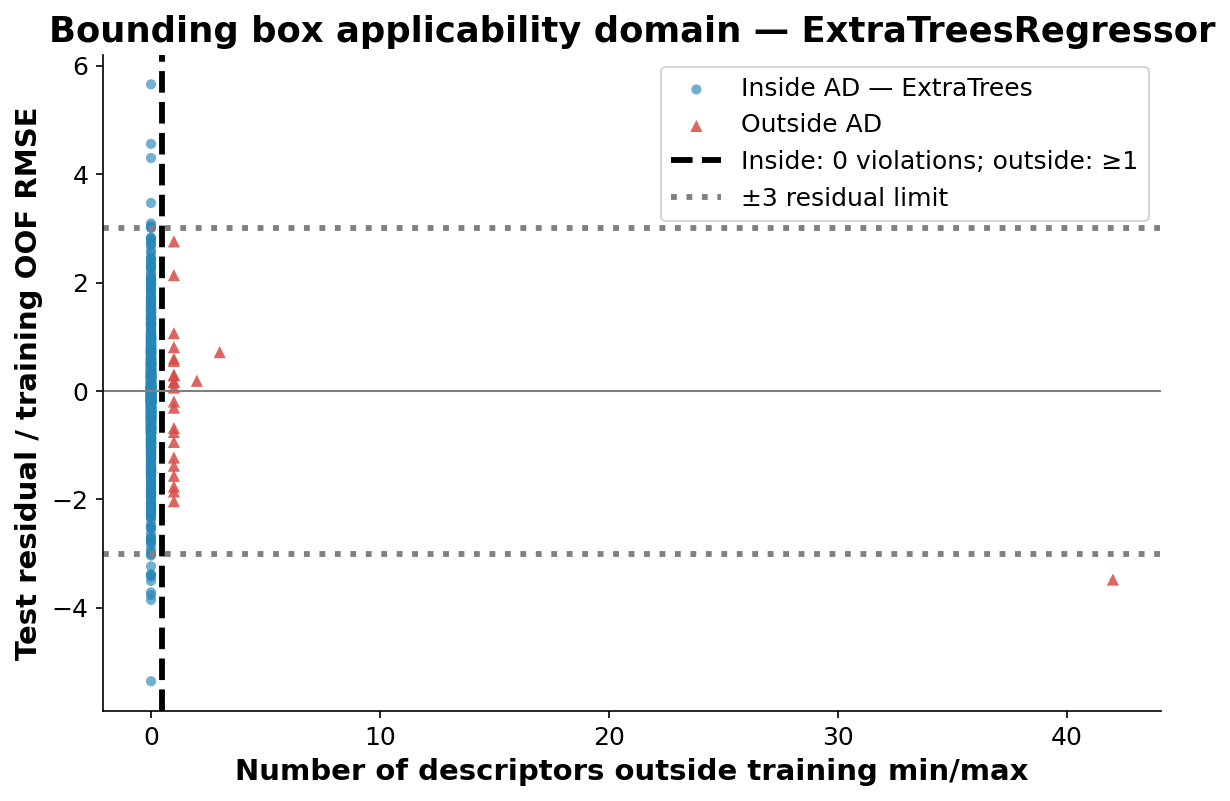

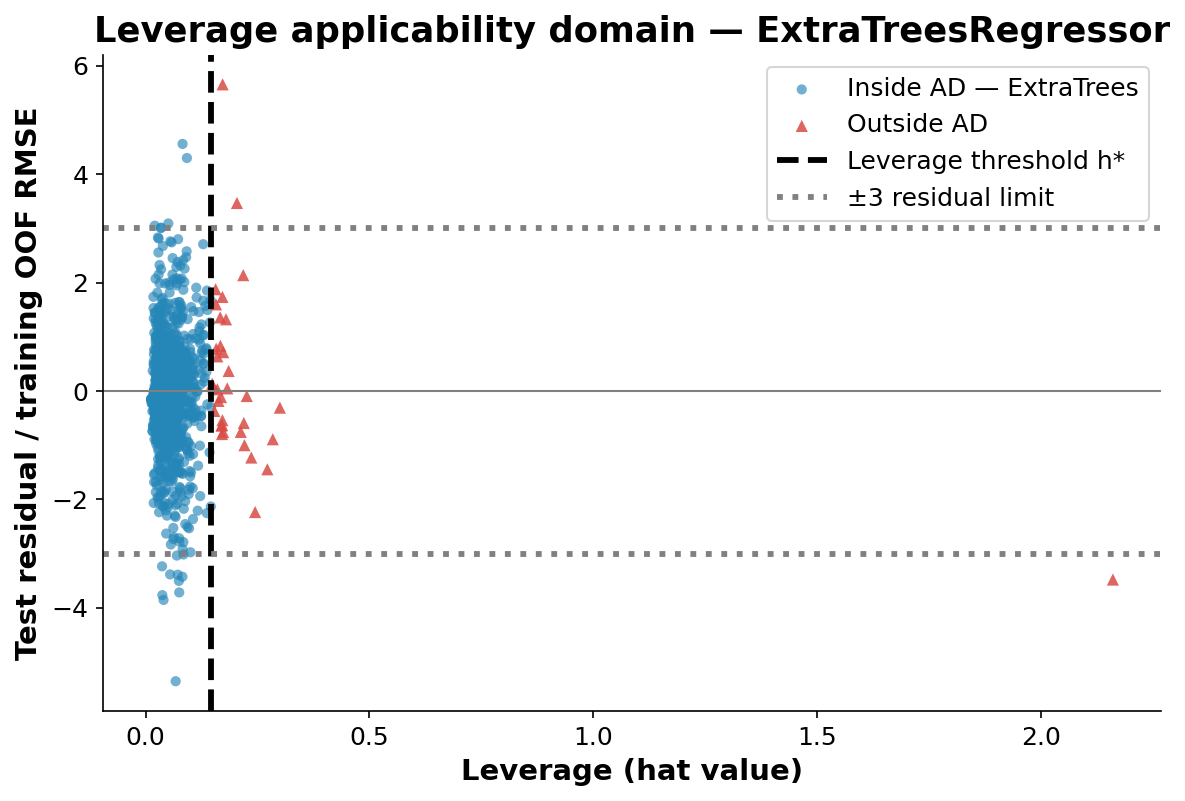

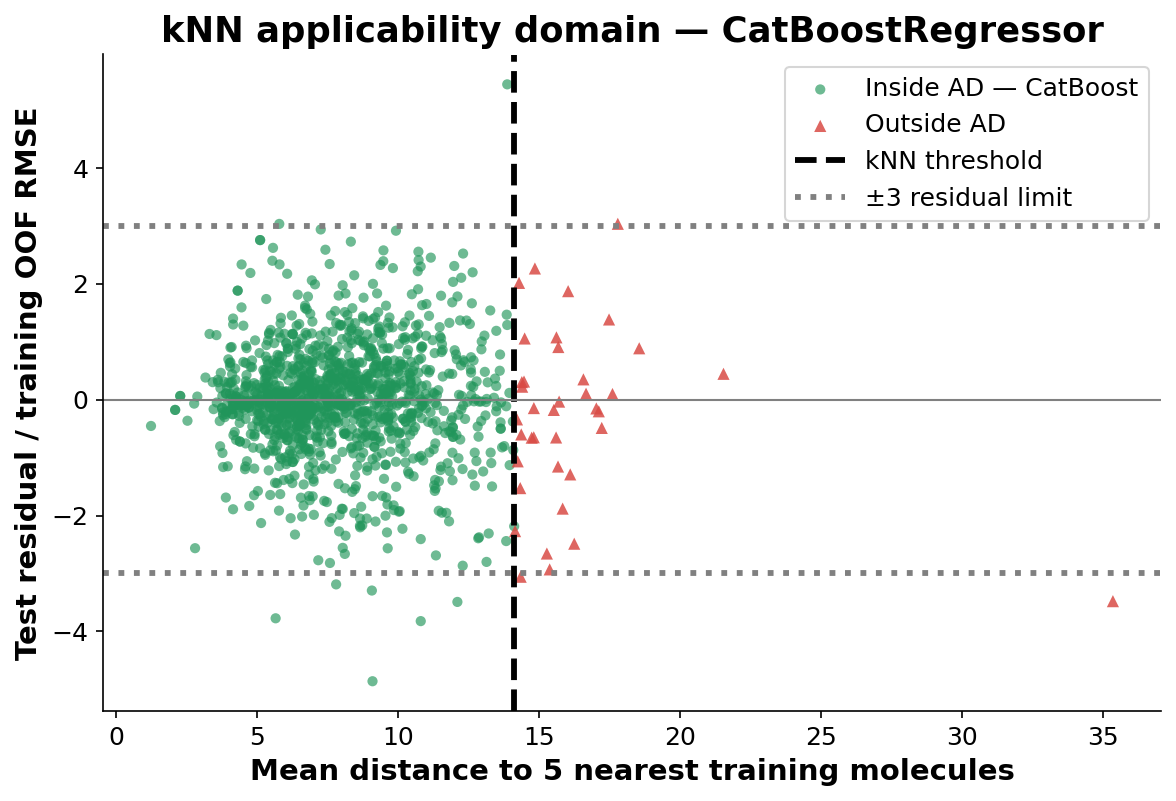

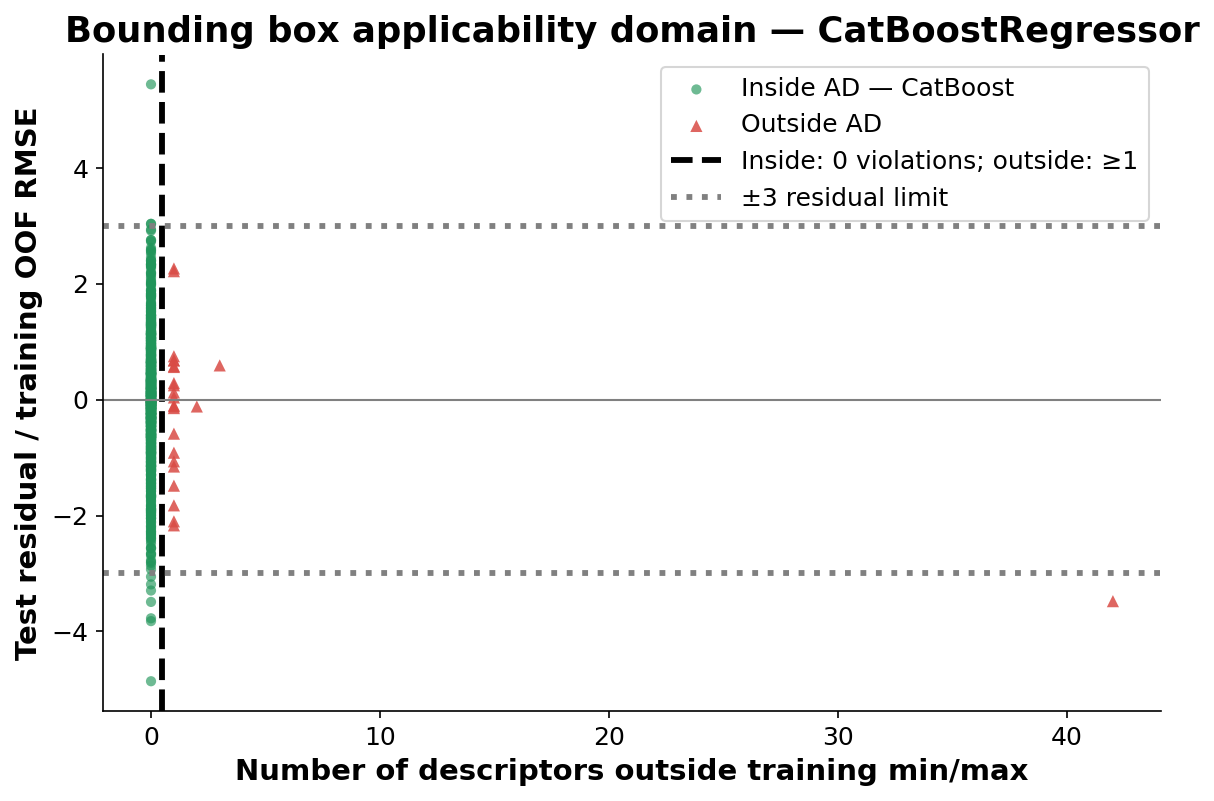

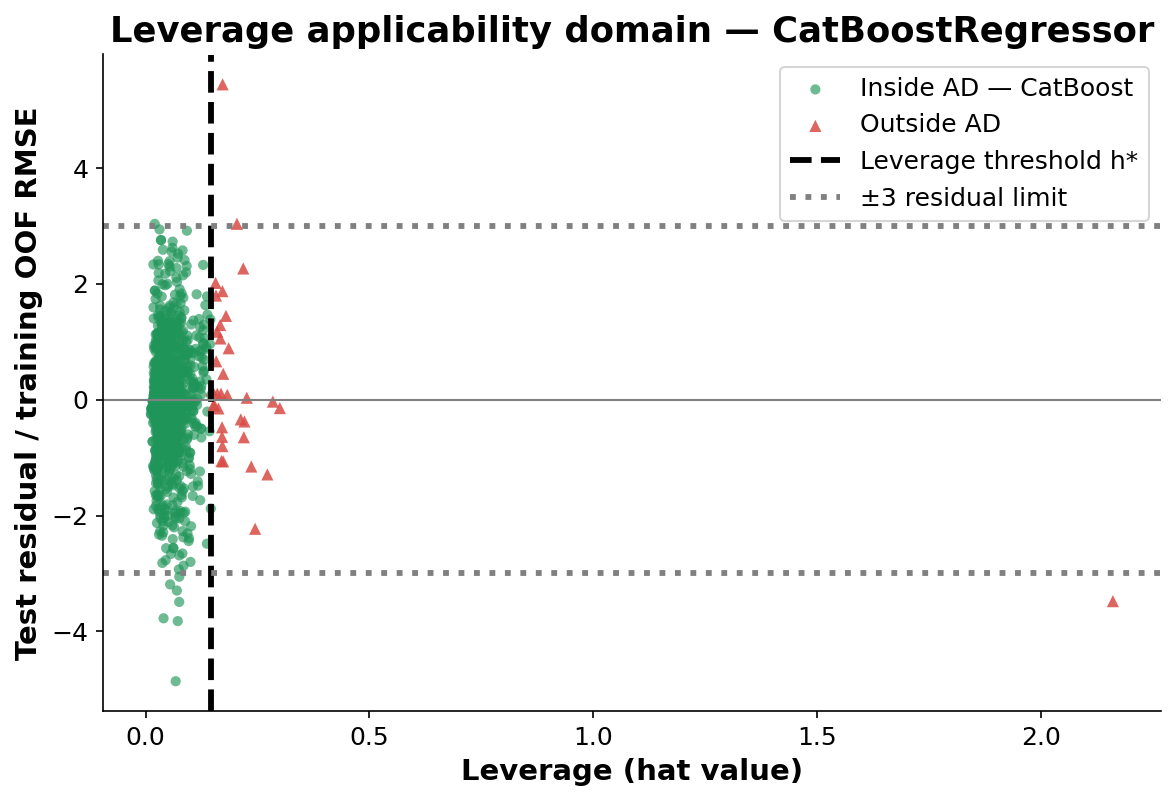

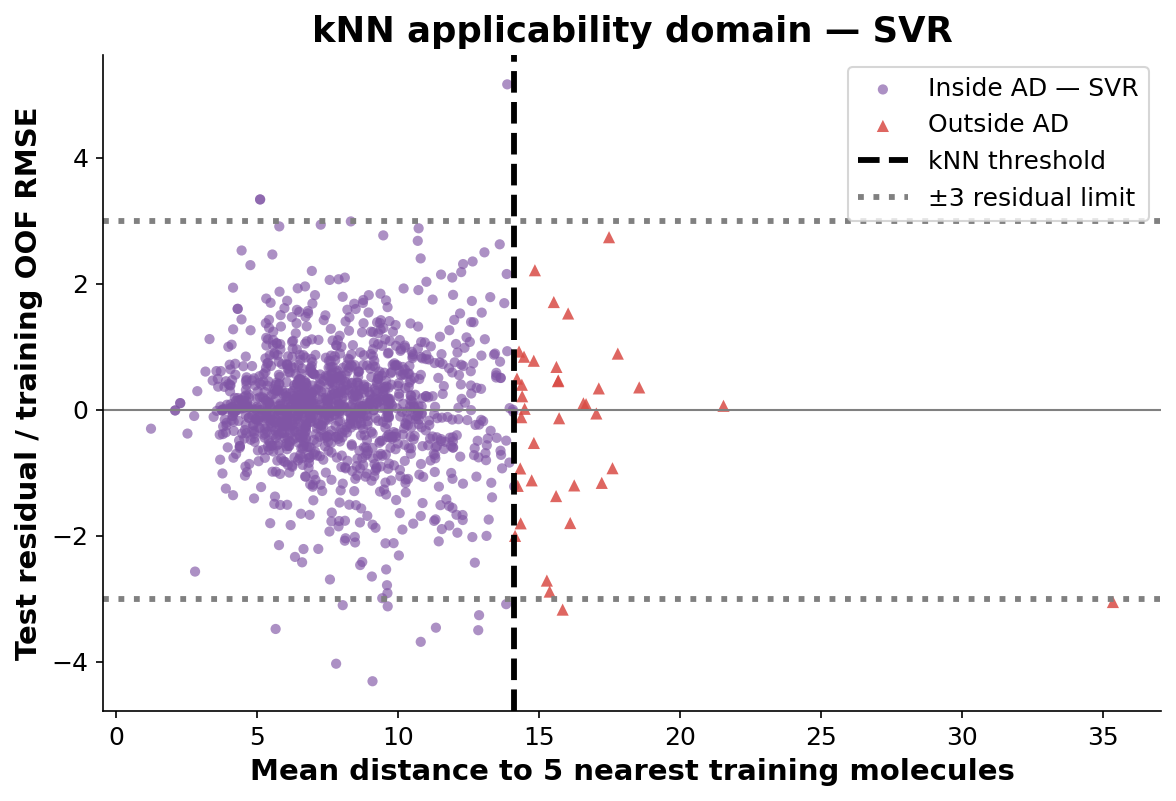

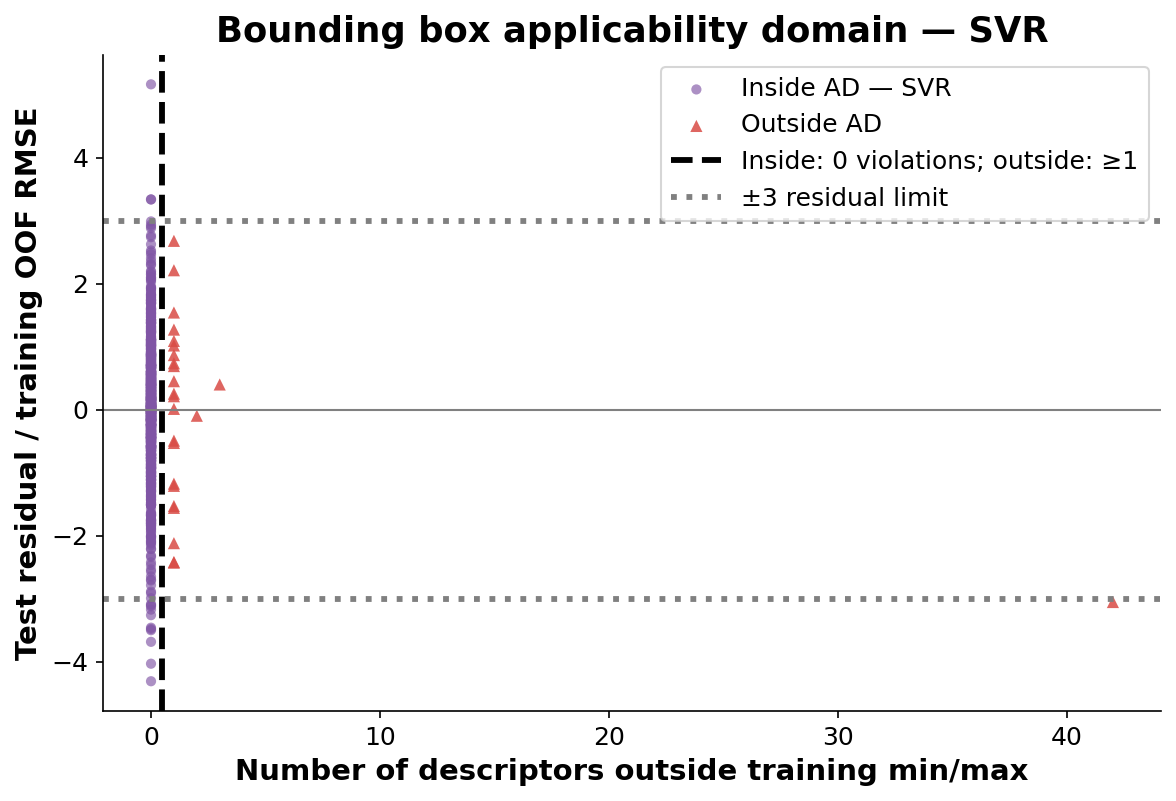

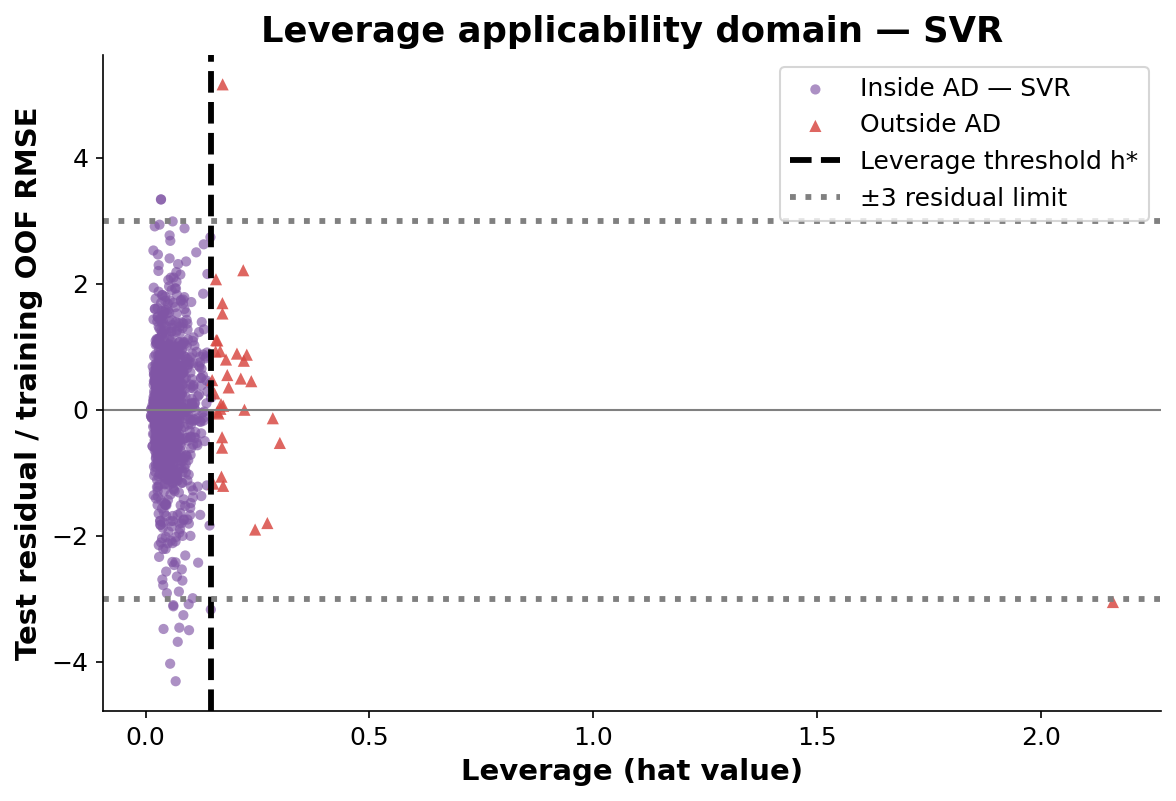

Saved 9 plots as PNG and PDF in: C:\Users\USER\Documents\E\Code\outputs\09b_applicability_domain\figures


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from src.utils import OUTPUTS

# Run this cell after the Stage 09b cell that defines test_ad.
oof_path = OUTPUTS / "08_final_model_evaluation/tables/fresh_cv_oof_predictions_all_models.csv"
oof = pd.read_csv(oof_path)

plot_dir = OUTPUTS / "09b_applicability_domain/figures"
plot_dir.mkdir(parents=True, exist_ok=True)

models = ["ExtraTreesRegressor", "CatBoostRegressor", "SVR"]

# Unique inside-domain colour for each model; outside-domain points stay red.
inside_colors = {
    "ExtraTreesRegressor": "#2586B8",  # blue
    "CatBoostRegressor": "#20955A",    # green
    "SVR": "#8055A5",                  # purple
}
outside_color = "#D94B45"

methods = {
    "kNN": {
        "x": "mean_5nn_distance",
        "inside": "inside_knn_ad",
        "xlabel": "Mean distance to 5 nearest training molecules",
        "threshold": float(test_ad["knn_threshold"].iloc[0]),
        "limit_label": "kNN threshold",
        "filename": "knn",
    },
    "Bounding box": {
        "x": "out_of_bounds_feature_count",
        "inside": "inside_bounding_box_ad",
        "xlabel": "Number of descriptors outside training min/max",
        "threshold": 0.5,  # 0 violations = inside; 1 or more = outside
        "limit_label": "Inside: 0 violations; outside: ≥1",
        "filename": "bounding_box",
    },
    "Leverage": {
        "x": "leverage",
        "inside": "inside_leverage_ad",
        "xlabel": "Leverage (hat value)",
        "threshold": float(test_ad["leverage_threshold"].iloc[0]),
        "limit_label": "Leverage threshold h*",
        "filename": "leverage",
    },
}

for model in models:
    model_oof = oof.loc[oof["model"] == model]
    oof_rmse = np.sqrt(
        mean_squared_error(
            model_oof["observed_pIC50"],
            model_oof["predicted_pIC50"],
        )
    )

    for method_name, spec in methods.items():
        inside = test_ad[spec["inside"]].astype(bool).to_numpy()
        x = test_ad[spec["x"]].to_numpy(dtype=float)
        standardized_residual = (
            test_ad[f"residual_{model}"].to_numpy(dtype=float) / oof_rmse
        )

        fig, ax = plt.subplots(figsize=(8, 5.5))

        ax.scatter(
            x[inside],
            standardized_residual[inside],
            color=inside_colors[model],
            marker="o",
            s=24,
            alpha=0.65,
            edgecolors="none",
            label=f"Inside AD — {model.removesuffix('Regressor')}",
        )
        ax.scatter(
            x[~inside],
            standardized_residual[~inside],
            color=outside_color,
            marker="^",
            s=34,
            alpha=0.85,
            edgecolors="none",
            label="Outside AD",
        )

        ax.axvline(
            spec["threshold"],
            color="black",
            linestyle="--",
            label=spec["limit_label"],
        )
        ax.axhline(0, color="gray", linewidth=1)
        ax.axhline(3, color="gray", linestyle=":", label="±3 residual limit")
        ax.axhline(-3, color="gray", linestyle=":")

        ax.set_xlabel(spec["xlabel"])
        ax.set_ylabel("Test residual / training OOF RMSE")
        ax.set_title(f"{method_name} applicability domain — {model}")
        ax.legend()
        fig.tight_layout()

        filename = (
            f"ad_residual_{spec['filename']}_"
            f"{model.removesuffix('Regressor')}"
        )
        fig.savefig(plot_dir / f"{filename}.png", dpi=300, bbox_inches="tight")
        fig.savefig(plot_dir / f"{filename}.pdf", bbox_inches="tight")
        plt.show()
        plt.close(fig)

print(f"Saved 9 plots as PNG and PDF in: {plot_dir}")